# 01 · Data Exploration & Quality
Can the supplied feeds support a causal liquidation study without silently cleaning away market events?

Eight Parquet sources cover BTCUSDT and ETHUSDT perpetual futures, December 2025–February 2026:
Binance trades, BBO and liquidations, plus Bybit liquidations. This notebook replays the original full-row audit
from `artifacts/results/quality/`; it does not load the private ticks. The separate API example uses artificial data.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'pyproject.toml').exists())
sys.path.insert(0, str(ROOT/'src'))
sys.path.insert(0, str(ROOT))
from research_paths import artifact_dir
import research_report as report
report.style()
def show(fig, name):
    path=ROOT/'artifacts/figures'/name
    fig.savefig(path, dpi=150)
    display(Image(filename=str(path)))
    plt.close(fig)

## Coverage and schemas
`summary.csv` and `source_manifest.csv` were saved by the original audit. The manifest retains source SHA-256 values;
local absolute paths have been replaced by repository-relative paths. Equal timestamps and exact duplicate records
are distinct diagnostics. Identical trade records are not proof of duplicate executions.

In [2]:
quality=report.table('quality','summary.csv')
manifest=report.table('quality','source_manifest.csv')
assert quality.rows.sum()==1_315_384_304
assert manifest.rows.sum()==quality.rows.sum()
display(quality[['file','rows','columns','date range']])
print(f"Full audit: {quality.rows.sum():,} records in {len(quality)} files")

,file,rows,columns,date range
0,data/raw/binance_booktickers/perp_btcusdt.parquet,99169477,6,2025-12-01 00:00:02.075000+00:00 → 2026-02-28 ...
1,data/raw/binance_booktickers/perp_ethusdt.parquet,107797036,6,2025-12-01 00:00:00.683000+00:00 → 2026-02-28 ...
2,data/raw/binance_liquidations/perp_btcusdt.par...,114255,5,2025-12-01 00:00:06.091000+00:00 → 2026-02-28 ...
3,data/raw/binance_liquidations/perp_ethusdt.par...,131769,5,2025-12-01 00:00:09.455000+00:00 → 2026-02-28 ...
4,data/raw/binance_trades/perp_btcusdt.parquet,401902513,5,2025-12-01 00:00:00.047000+00:00 → 2026-02-28 ...
5,data/raw/binance_trades/perp_ethusdt.parquet,705880385,5,2025-12-01 00:00:00.016000+00:00 → 2026-02-28 ...
6,data/raw/bybit_liquidations/btcusdt.parquet,228655,5,2025-12-01 00:00:02.915000+00:00 → 2026-02-28 ...
7,data/raw/bybit_liquidations/ethusdt.parquet,160214,5,2025-12-01 00:00:07.779000+00:00 → 2026-02-28 ...


Full audit: 1,315,384,304 records in 8 files


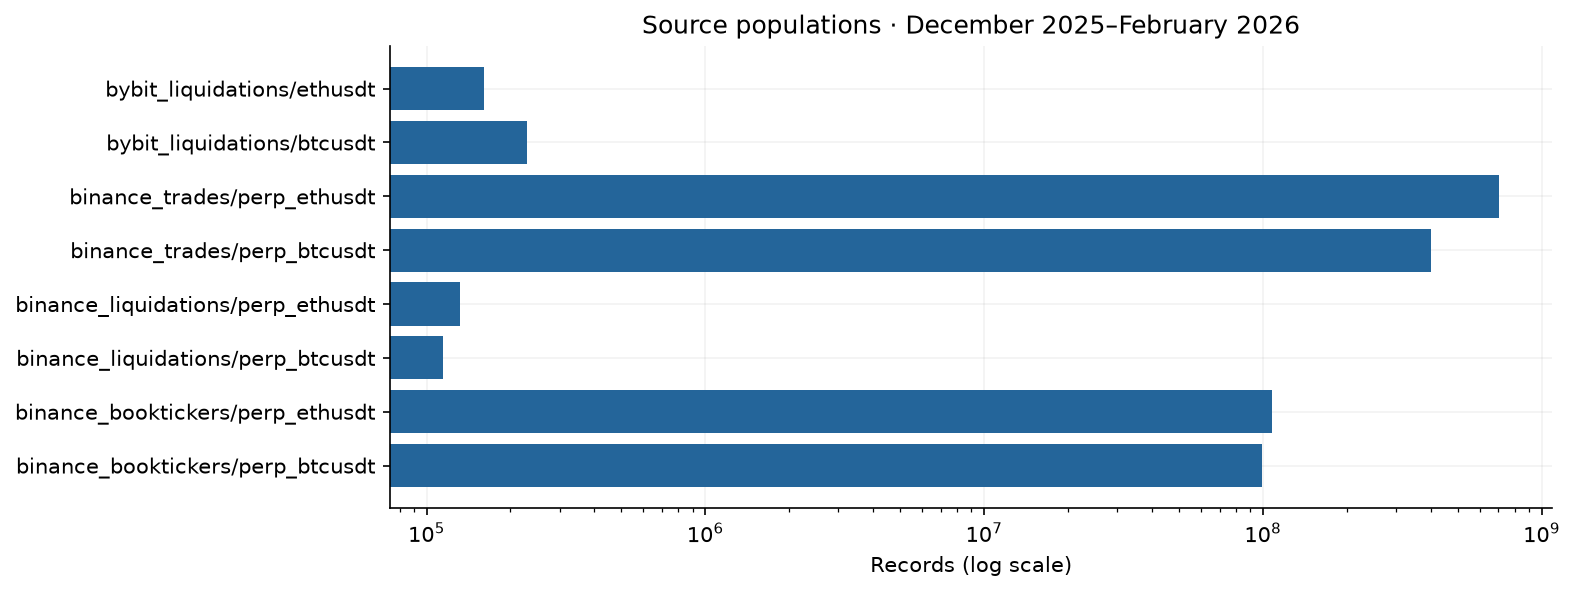

In [3]:
fig,ax=plt.subplots(figsize=(10,4))
labels=quality.file.str.replace('data/raw/','',regex=False).str.replace('.parquet','',regex=False)
ax.barh(labels,quality.rows,color='#24659a')
ax.set(xscale='log',xlabel='Records (log scale)',title='Source populations · December 2025–February 2026')
show(fig,'source_coverage.png')

## Missingness, duplicates and gaps
The audit uses integer UTC microseconds. Bybit availability is delayed by 200 ms for cross-feed analysis.
Long liquidation inter-arrivals can reflect an inactive feed; a missing BBO interval requires a different interpretation.
Suspect observations and market-event candidates remain separate from clear schema errors.

In [4]:
cols=['file','NaN count','timestamp reversals','duplicate timestamps','exact duplicate rows',
      'invalid prices','invalid amounts','largest time gap','number of removed observations']
display(quality[cols])
display(report.table('quality','window_reconciliation.csv'))
integrity=report.table('quality','source_integrity_verification.csv')
assert integrity.unchanged.all()
assert (integrity.sha256_before==integrity.sha256_after).all()

,file,NaN count,timestamp reversals,duplicate timestamps,exact duplicate rows,invalid prices,invalid amounts,largest time gap,number of removed observations
0,data/raw/binance_booktickers/perp_btcusdt.parquet,0,0,0,0,0,0,199.341000,0
1,data/raw/binance_booktickers/perp_ethusdt.parquet,0,0,0,0,0,0,354.007000,0
2,data/raw/binance_liquidations/perp_btcusdt.par...,0,0,0,0,0,0,"5,676.127000",0
3,data/raw/binance_liquidations/perp_ethusdt.par...,0,0,0,0,0,0,"6,812.221000",0
4,data/raw/binance_trades/perp_btcusdt.parquet,0,0,316865596,77816720,0,0,46.431000,0
5,data/raw/binance_trades/perp_ethusdt.parquet,0,0,597583948,138988014,0,0,46.261000,0
6,data/raw/bybit_liquidations/btcusdt.parquet,0,63,5094,1,0,0,"32,396.339000",0
7,data/raw/bybit_liquidations/ethusdt.parquet,0,46,2664,2,0,0,"19,957.501000",0


,symbol,severity,source,center_second,count,raw_notional,aggregate_notional,absolute_difference
0,btcusdt,SUSPICIOUS,trades,1764871317,571,"1,323,163.540700","1,323,163.540710",0.000010
1,btcusdt,SUSPICIOUS,binance_liq,1764871317,3,"3,580.538450","3,580.538450",0.000000
2,btcusdt,SUSPICIOUS,bybit_liq,1764871317,1,277.956000,277.956000,0.000000
3,btcusdt,PLAUSIBLE_MARKET_EVENT,trades,1768342251,20115,"155,608,139.340900","155,608,139.340942",0.000042
4,btcusdt,PLAUSIBLE_MARKET_EVENT,binance_liq,1768342251,7,"179,470.597400","179,470.597400",0.000000
5,btcusdt,PLAUSIBLE_MARKET_EVENT,bybit_liq,1768342251,150,"8,061,057.319100","8,061,057.319100",0.000000
6,ethusdt,SUSPICIOUS,trades,1766497241,2182,"3,099,169.235830","3,099,169.235901",0.000071
7,ethusdt,SUSPICIOUS,binance_liq,1766497241,2,"11,304.448400","11,304.448400",0.000000
8,ethusdt,SUSPICIOUS,bybit_liq,1766497241,0,0.000000,0.000000,0.000000
9,ethusdt,PLAUSIBLE_MARKET_EVENT,trades,1768342250,35572,"141,546,805.993830","141,546,805.993896",0.000066


The saved audit contains no missing cells or invalid basic prices/amounts. Bybit has 63 BTC and 46 ETH timestamp
reversals in physical file order. It also contains exact duplicate trades and long BBO gaps. These findings do not establish that all observed prices
are economically plausible. The maker study retains flagged liquidation prices and reports a cleaning sensitivity;
the warning study has its own explicitly documented predictor cleaning.

## Portable data access
These eight CSV fixtures are generated independently of the market dataset. They exercise the public schema,
timestamp units and submission interface; their prices and outcomes are not evidence about the strategies.

In [5]:
sample=ROOT/'data/sample'
trades=pd.read_csv(sample/'binance_trades/perp_btcusdt.csv')
bbo=pd.read_csv(sample/'binance_booktickers/perp_btcusdt.csv')
display(trades.head(4))
display(bbo.head(4))
assert trades.timestamp.dtype==np.dtype('int64')
assert set(trades.side)=={'buy','sell'}

,timestamp,ticker,side,price,amount
0,1767225600500000,perp:btcusdt,sell,"100,002.886548",0.177370
1,1767225601500000,perp:btcusdt,buy,"100,005.308798",0.144879
2,1767225602500000,perp:btcusdt,sell,"99,992.384776",0.035768
3,1767225603500000,perp:btcusdt,buy,"99,995.775373",0.197370


,timestamp,ticker,bid_price,bid_amount,ask_price,ask_amount
0,1767225599999999,perp:btcusdt,"100,002.886548",1.209217,"100,004.886626",3.398367
1,1767225600999999,perp:btcusdt,"100,003.308712",2.030018,"100,005.308798",4.649197
2,1767225601999999,perp:btcusdt,"99,992.384776",4.820374,"99,994.384644",1.950272
3,1767225602999999,perp:btcusdt,"99,993.775478",3.181939,"99,995.775373",3.713817


## Conclusion
The supplied sources passed the recorded structural checks, but duplicates, staleness and liquidation price flags
still matter. Raw-data redistribution rights are undocumented, so no original rows are published.
`python -m data_quality_audit` performs the original full audit when authorized files are supplied;
see [data access](../data/README.md) and [rerun instructions](../docs/reproducibility.md).